# WiPER Benchmarking — v10: fase robusta e test di deriva

Stesso protocollo di v7–v9 (k-fold sulle identità, 4 protocolli per registrazione, chance esatta). Legge ampiezze e `csi_matrices` prodotte da *WiPER-DataProcessing*.

**Due domande, dopo i risultati v9** (la fase dà ~+4 punti di mAP, ma `ph_std`/`ph_diff` hanno la deriva più forte con il numero soggetto)

| # | Domanda | Sezione |
|---|---|---|
| 1 | La fase "classica" (srotolamento + rimozione lineare) è inquinata da errori di srotolamento? La **differenza di fase fra sottoportanti adiacenti** `angle(H_k · conj(H_{k-1}))` non richiede srotolamento e annulla l'offset di pacchetto: è migliore? | §3, §5 |
| 2 | Quanta accuratezza **sopravvive** se si rimuove dalle feature il sottospazio lungo cui i soggetti variano lentamente con il numero soggetto (la "sessione")? Con **controllo**: stessa operazione con i numeri dei soggetti di training permutati a caso | §6–§7 |

### Perché non si "sottrae il trend per soggetto"
Una prima versione sottraeva a ogni registrazione il trend lento stimato per il suo soggetto. È **sbagliato**: la quantità sottratta è una costante specifica del soggetto (dipende dal suo numero), quindi *aggiunge identità alle feature* e rende i soggetti più separabili (il controllo con ordine permutato saliva da 52% a 95% di mAP sui dati sintetici). Qui invece si usa una **proiezione lineare fissa**:

1. In ogni fold, sui soli soggetti di **training**, si stima il trend lento delle medie per soggetto in funzione del numero (kernel gaussiano o polinomio).
2. Le prime `k` direzioni principali di quel trend formano il **sottospazio di deriva** `V`.
3. Tutte le registrazioni (training e test) vengono proiettate fuori da `V`: `x' = x − V Vᵀ x`. La mappa è la stessa per tutti e **non usa il numero dei soggetti di test**: nessuna fuga di identità.
4. **Controllo**: stessa procedura con i numeri dei soggetti di training permutati (stessa dimensione `k`, stesso metodo, nessuna vera deriva).

**perdita netta = controllo − reale**: l'accuratezza che sparisce *solo* togliendo le vere direzioni di deriva. Alta e positiva ⇒ quella parte era legata al tempo/sessione. ≈ 0 ⇒ non spiegata dalla numerazione.

> Assume che la numerazione segua l'ordine di acquisizione. Rimuovere un sottospazio toglie anche l'eventuale identità che vive lì: la perdita netta è un limite superiore della quota "sessione", non una misura esatta.

## 1. Imports e configurazione

In [1]:
import os, re, random, time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import rankdata, spearmanr
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

pd.set_option('display.max_columns', None); pd.set_option('display.width', 250)

CFG = dict(
    seed=42,
    output_folder='./output/',
    sanitization='zscore',            # ampiezze: 'raw' | 'hampel' | 'zscore' | 'iqr'
    exclude_ids=('vuoto',),
    gallery_action='saluto', probe_action='tpose',
    n_subcarriers=52,
    phase_outlier_z=3.0,              # filtro |z|>soglia sulle serie temporali di fase (None = nessuno)
    pd_remove_common=True,            # differenza di fase: sottrae per pacchetto la componente comune (= pendenza)
    n_folds=4,
    # --- detrend ---
    detrend_variants=[('kernel', 3), ('poly', 3)],   # (metodo, parametro): kernel = larghezza in numeri soggetto, poly = grado
    drift_k=(2, 4, 8, 16),            # dimensioni del sottospazio di deriva da rimuovere (limitate al rango del trend)
    n_ctrl=3,                         # permutazioni di controllo
    drift_perms=2000,
)

SANITIZATION_DIRS = {
    'raw':    ('CSV', 'raw_amplitudes'),
    'hampel': ('CSV', 'sanitized_amplitudes', 'HF_amplitudes'),
    'zscore': ('CSV', 'sanitized_amplitudes', 'zscore_amplitudes'),
    'iqr':    ('CSV', 'sanitized_amplitudes', 'iqr_amplitudes'),
}
amp_dir = os.path.join(CFG['output_folder'], *SANITIZATION_DIRS[CFG['sanitization']])
csi_dir = os.path.join(CFG['output_folder'], 'CSV', 'csi_matrices')
random.seed(CFG['seed']); np.random.seed(CFG['seed'])

## 2. Caricamento e fold

In [2]:
KEY_RE = re.compile(r'^(?P<sid>[^_]+)_(?P<act>[A-Za-z]+)(?P<num>\d+)$')
assert os.path.isdir(amp_dir), f'Cartella non trovata: {amp_dir}'
assert os.path.isdir(csi_dir), f'Cartella non trovata: {csi_dir}'

def load_amp(key):
    return pd.read_csv(os.path.join(amp_dir, key + '.csv')).drop(columns='timestamp', errors='ignore').to_numpy(dtype=np.float64)

def load_csi(key):
    df = pd.read_csv(os.path.join(csi_dir, key + '.csv')).drop(columns='timestamp', errors='ignore')
    return df.to_numpy().astype(str).astype(complex)

recs = []
for fname in sorted(os.listdir(amp_dir)):
    if not fname.endswith('.csv'): continue
    key = fname[:-4]
    if key.split('_')[0] in CFG['exclude_ids']: continue
    m = KEY_RE.match(key)
    if not m: print('ignorato:', key); continue
    A, H = load_amp(key), load_csi(key)
    assert A.shape == H.shape == (A.shape[0], CFG['n_subcarriers']), f'{key}: forme incoerenti {A.shape} vs {H.shape}'
    recs.append(dict(sid=m.group('sid'), act=m.group('act').lower(), num=int(m.group('num')), rec_id=key, A=A, H=H))

R = len(recs)
rec_sid = np.array([r['sid'] for r in recs]); rec_act = np.array([r['act'] for r in recs])
GAL, PRB = CFG['gallery_action'], CFG['probe_action']
assert GAL in set(rec_act) and PRB in set(rec_act)
print(f'{R} registrazioni | {len(set(rec_sid))} identità')

def natural_key(s): return [int(t) if t.isdigit() else t for t in re.split(r'(\d+)', s)]
all_ids = sorted(set(rec_sid), key=natural_key)
rng = np.random.RandomState(CFG['seed']); perm = rng.permutation(len(all_ids))
fold_ids = [set(all_ids[i] for i in chunk) for chunk in np.array_split(perm, CFG['n_folds'])]
folds = [(np.where(~np.isin(rec_sid, list(t)))[0], np.where(np.isin(rec_sid, list(t)))[0]) for t in fold_ids]
print('Fold (identità test / train):', [(len(t), len(set(rec_sid[tr]))) for t, (tr, _) in zip(fold_ids, folds)])

440 registrazioni | 44 identità
Fold (identità test / train): [(11, 33), (11, 33), (11, 33), (11, 33)]


## 3. Fase classica (srotolamento) contro fase robusta (differenza fra sottoportanti adiacenti)

In [3]:
def phase_residual(H):
    # fase classica: srotola lungo le sottoportanti, toglie offset+pendenza per pacchetto
    ph = np.unwrap(np.angle(H), axis=1)
    k = np.arange(H.shape[1]).astype(float); kc = k - k.mean()
    slope = (ph * kc).sum(axis=1) / (kc ** 2).sum()
    icpt = ph.mean(axis=1) - slope * k.mean()
    return ph - (slope[:, None] * k[None, :] + icpt[:, None]), slope, icpt

def zscore_fill(M, thr):
    if thr is None: return M
    mu, sd = M.mean(0), M.std(0) + 1e-12
    return pd.DataFrame(M).mask(np.abs((M - mu) / sd) > thr).ffill().bfill().to_numpy()

def pd_groups(H, remove_common):
    # fase robusta: differenza di fase fra sottoportanti adiacenti (avvolta, nessun unwrap), offset di pacchetto annullato
    C = H[:, 1:] * np.conj(H[:, :-1])                                   # [T, 51]
    dphi = np.angle(C)
    if remove_common:
        common = np.angle(C.sum(axis=1, keepdims=True))                 # pendenza media del pacchetto (pesata dall'ampiezza)
        dphi = np.angle(np.exp(1j * (dphi - common)))
    z = np.exp(1j * dphi); mv = z.mean(axis=0)
    dd = np.angle(np.exp(1j * np.diff(dphi, axis=0)))
    return {'static': np.concatenate([mv.real, mv.imag]),               # media circolare (continua: parte reale/immaginaria)
            'std':    np.sqrt(-2.0 * np.log(np.clip(np.abs(mv), 1e-6, 1.0))),   # deviazione standard circolare nel tempo
            'diff':   np.abs(dd).mean(axis=0)}

# --- diagnostica: errori di srotolamento? ---
rows = []
for r in recs:
    res, slope, _ = phase_residual(r['H'])
    n_wraps = (np.abs(np.diff(np.angle(r['H']), axis=1)) > np.pi).sum(axis=1).mean()      # salti di 2π corretti da unwrap, per pacchetto
    rows.append({'rec': r['rec_id'], 'salti unwrap/pacchetto': n_wraps, 'std pendenza': slope.std(),
                 'std residuo classico (rad)': res.std(0).mean(), 'std circolare robusta (rad)': pd_groups(r['H'], True)['std'].mean()})
diag = pd.DataFrame(rows).set_index('rec')
print('Registrazioni con il residuo classico più alto:')
display(diag.sort_values('std residuo classico (rad)', ascending=False).head(8).round(3))
c1 = spearmanr(diag['salti unwrap/pacchetto'], diag['std residuo classico (rad)'])[0]
c2 = spearmanr(diag['salti unwrap/pacchetto'], diag['std circolare robusta (rad)'])[0]
print(f'Spearman(salti unwrap, residuo classico) = {c1:.2f} | Spearman(salti unwrap, std robusta) = {c2:.2f}')
print(f"Registrazioni con >0.05 salti/pacchetto: {(diag['salti unwrap/pacchetto'] > 0.05).sum()} su {len(diag)}")
print('Se la prima correlazione è alta e la seconda no, il residuo classico è gonfiato da errori di srotolamento.')

Registrazioni con il residuo classico più alto:


,salti unwrap/pacchetto,std pendenza,std residuo classico (rad),std circolare robusta (rad)
rec,,,,
soggetto10_tPose2,0.869,0.040,0.517,0.172
soggetto14_saluto3,1.199,0.060,0.509,0.189
soggetto2_saluto2,1.566,0.070,0.507,0.220
soggetto19_saluto4,0.923,0.058,0.401,0.157
soggetto10_saluto1,0.853,0.034,0.373,0.154
soggetto5_saluto4,0.723,0.025,0.372,0.195
soggetto10_tPose3,0.623,0.026,0.371,0.164
soggetto10_tPose5,0.676,0.030,0.370,0.140


Spearman(salti unwrap, residuo classico) = 0.50 | Spearman(salti unwrap, std robusta) = 0.54
Registrazioni con >0.05 salti/pacchetto: 440 su 440
Se la prima correlazione è alta e la seconda no, il residuo classico è gonfiato da errori di srotolamento.


## 4. Feature per registrazione

In [4]:
def amp_groups(A):
    X = A / (A.mean() + 1e-8)
    return {'static': X.mean(0), 'dyn_std': X.std(0), 'diff': np.abs(np.diff(X, axis=0)).mean(0)}

def classic_phase_groups(H):
    res, slope, icpt = phase_residual(H)
    res = zscore_fill(res, CFG['phase_outlier_z'])
    return {'ph_static': res.mean(0), 'ph_std': res.std(0), 'ph_diff': np.abs(np.diff(res, axis=0)).mean(0),
            'ph_sto': np.array([slope.mean(), slope.std(), np.abs(np.diff(slope)).mean(),
                                np.abs(np.exp(1j * icpt).mean()), np.abs(np.angle(np.exp(1j * np.diff(icpt)))).mean()])}

t0 = time.time(); out = defaultdict(list)
for r in recs:
    g = amp_groups(r['A']); g.update(classic_phase_groups(r['H']))
    for tag, rc in [('pd', CFG['pd_remove_common']), ('pdn', not CFG['pd_remove_common'])]:   # pd = scelta di config; pdn = alternativa per il confronto
        for k, v in pd_groups(r['H'], rc).items(): g[f'{tag}_{k}'] = v
    for k, v in g.items(): out[k].append(v)
feat = {k: np.stack(v) for k, v in out.items()}
GROUPS = ['static', 'dyn_std', 'diff', 'ph_static', 'ph_std', 'ph_diff', 'pd_static', 'pd_std', 'pd_diff', 'pdn_static', 'pdn_std', 'pdn_diff', 'ph_sto']
print(f'feature in {time.time() - t0:.1f}s |', {g: feat[g].shape[1] for g in GROUPS})
print('NaN/inf:', {g: int((~np.isfinite(feat[g])).sum()) for g in GROUPS if (~np.isfinite(feat[g])).any()} or 'nessuno')

FEATURE_SETS = {
    'amp static':          ['static'],
    'amp basic':           ['static', 'dyn_std', 'diff'],
    'ph all (classica)':   ['ph_static', 'ph_std', 'ph_diff'],
    'ph dyn (classica)':   ['ph_std', 'ph_diff'],
    'pd all (robusta)':    ['pd_static', 'pd_std', 'pd_diff'],
    'pd dyn (robusta)':    ['pd_std', 'pd_diff'],
    'pdn all (senza tolta comune)': ['pdn_static', 'pdn_std', 'pdn_diff'],
    'amp static + pd all': ['static', 'pd_static', 'pd_std', 'pd_diff'],
    'amp basic + pd all':  ['static', 'dyn_std', 'diff', 'pd_static', 'pd_std', 'pd_diff'],
    'amp basic + ph all':  ['static', 'dyn_std', 'diff', 'ph_static', 'ph_std', 'ph_diff'],
    'DIAG ph_sto (hardware)': ['ph_sto'],
}
XS = {n: np.concatenate([feat[g] for g in gs], axis=1) for n, gs in FEATURE_SETS.items()}
print({n: x.shape[1] for n, x in XS.items()})

feature in 5.5s | {'static': 52, 'dyn_std': 52, 'diff': 52, 'ph_static': 52, 'ph_std': 52, 'ph_diff': 52, 'pd_static': 102, 'pd_std': 51, 'pd_diff': 51, 'pdn_static': 102, 'pdn_std': 51, 'pdn_diff': 51, 'ph_sto': 5}
NaN/inf: nessuno
{'amp static': 52, 'amp basic': 156, 'ph all (classica)': 156, 'ph dyn (classica)': 104, 'pd all (robusta)': 204, 'pd dyn (robusta)': 102, 'pdn all (senza tolta comune)': 204, 'amp static + pd all': 256, 'amp basic + pd all': 360, 'amp basic + ph all': 312, 'DIAG ph_sto (hardware)': 5}


## 5. Metriche, protocolli e confronto fase classica / robusta

In [5]:
def expected_ap_random(n, p):
    if n <= 1: return 1.0
    i = np.arange(1, n + 1)
    return float(np.sum((1.0 / i) * (1 + (i - 1) * (p - 1) / (n - 1))) / n)

def rank_metrics(q_feats, q_ids, g_feats, g_ids, exclude_self=False):
    sim = q_feats @ g_feats.T
    q_ids, g_ids = np.asarray(q_ids), np.asarray(g_ids)
    matches = q_ids[:, None] == g_ids[None, :]
    if exclude_self:
        np.fill_diagonal(sim, -np.inf); np.fill_diagonal(matches, False)
    valid = matches.sum(1) > 0
    sim, matches = sim[valid], matches[valid]
    if len(sim) == 0:
        return dict(rank1=np.nan, rank5=np.nan, mAP=np.nan, n_queries=0, chance_rank1=np.nan, chance_mAP=np.nan)
    order = np.argsort(-sim, axis=1, kind='stable')
    m = np.take_along_axis(matches, order, axis=1)
    cum = np.cumsum(m, axis=1)
    cmc = (cum > 0).mean(axis=0) * 100.0
    ap = ((cum / (np.arange(m.shape[1]) + 1)) * m).sum(axis=1) / m.sum(axis=1)
    n_gal = matches.shape[1] - (1 if exclude_self else 0); pos = matches.sum(1)
    return dict(rank1=cmc[0], rank5=cmc[min(4, len(cmc) - 1)], mAP=ap.mean() * 100.0, n_queries=len(sim),
                chance_rank1=(pos / n_gal).mean() * 100.0,
                chance_mAP=np.mean([expected_ap_random(n_gal, p) for p in pos]) * 100.0)

PROTOCOLS = ['cross', 'cross_rev', f'same_{GAL}', f'same_{PRB}']

def eval_protocols(E, sid, act):
    G, Pm = act == GAL, act == PRB
    return {'cross':       rank_metrics(E[Pm], sid[Pm], E[G],  sid[G]),
            'cross_rev':   rank_metrics(E[G],  sid[G],  E[Pm], sid[Pm]),
            f'same_{GAL}': rank_metrics(E[G],  sid[G],  E[G],  sid[G],  exclude_self=True),
            f'same_{PRB}': rank_metrics(E[Pm], sid[Pm], E[Pm], sid[Pm], exclude_self=True)}

def l2(Z): return Z / (np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12)

def aggregate_folds(res_list):
    out = {}
    for k in PROTOCOLS:
        w = np.array([r[k]['n_queries'] for r in res_list], float)
        for m in ['rank1', 'mAP', 'chance_rank1', 'chance_mAP']:
            v = np.array([r[k][m] for r in res_list]); out[(k, m)] = float((w * v).sum() / w.sum())
        for m in ['rank1', 'mAP']:
            out[(k, m + '_std')] = float(np.std([r[k][m] for r in res_list]))
    return out

def mean_map(res): return float(np.mean([res[k]['mAP'] for k in PROTOCOLS]))

def embed_lda(X, train_idx):
    mu, sd = X[train_idx].mean(0), X[train_idx].std(0) + 1e-8
    Z = (X - mu) / sd
    lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto').fit(Z[train_idx], rec_sid[train_idx])
    return l2(lda.transform(Z))

def run_cv(X):
    return [eval_protocols(embed_lda(X, tr)[te], rec_sid[te], rec_act[te]) for tr, te in folds]

def results_table(store):
    rows = []; ch = aggregate_folds(next(iter(store.values())))
    rows.append({'metodo': 'CHANCE', **{f'{k} {m}': ch[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'chance_rank1'), ('mAP', 'chance_mAP')]}})
    for name, res in store.items():
        a = aggregate_folds(res)
        rows.append({'metodo': name, **{f'{k} {m}': a[(k, key)] for k in PROTOCOLS for m, key in [('R1', 'rank1'), ('mAP', 'mAP')]},
                     'mAP media4': np.mean([a[(k, 'mAP')] for k in PROTOCOLS])})
    return pd.DataFrame(rows).set_index('metodo').round(1)

store = {n: run_cv(XS[n]) for n in FEATURE_SETS}
chance_mean4 = np.mean([aggregate_folds(next(iter(store.values())))[(k, 'chance_mAP')] for k in PROTOCOLS])
print('Chance mAP media4: %.1f' % chance_mean4)
print('=== Fase classica vs robusta (LDA, Rank-1 % / mAP %) ===')
display(results_table(store))

Chance mAP media4: 14.4
=== Fase classica vs robusta (LDA, Rank-1 % / mAP %) ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP,mAP media4
metodo,,,,,,,,,
CHANCE,9.1,15.1,9.1,15.1,7.4,13.7,7.4,13.7,NaN
amp static,30.0,30.0,26.4,28.6,48.6,41.6,40.0,36.9,34.3
amp basic,29.1,28.2,25.5,27.2,49.1,42.0,37.7,33.3,32.7
ph all (classica),31.8,33.1,33.2,32.6,50.5,46.5,41.4,41.2,38.4
ph dyn (classica),22.3,26.9,23.6,26.7,33.6,35.3,32.7,30.7,29.9
pd all (robusta),33.6,32.6,31.8,32.1,42.7,40.8,40.9,37.4,35.7
pd dyn (robusta),29.5,28.0,24.1,27.1,34.5,33.0,29.5,28.6,29.2
pdn all (senza tolta comune),33.2,32.6,30.9,32.1,41.4,40.8,42.7,37.6,35.7
amp static + pd all,37.3,34.8,31.4,33.8,47.7,44.3,45.9,40.5,38.3


## 6. Rimozione del sottospazio di deriva (stimato sul training) con controllo a ordine permutato

39s | chance mAP media4 = 14.4 | 3 permutazioni di controllo
"var. soggetti in V": quota della varianza fra soggetti (training) che cade nel sottospazio rimosso. Reale >> controllo = deriva forte.


k eff.  mAP originale  mAP reale  mAP controllo  perdita netta  ± std fold  % sopra chance  var. soggetti in V (reale %)  var. soggetti in V (ctrl %)  cross R1 orig  cross R1 reale  cross R1 ctrl
feature                variante     k                                                                                                                                                                                                      
amp static             kernel h=3   2      2.0           34.3       27.1           28.1            1.0         1.2             5.1                          94.9                         93.5           30.0            19.5           23.5
                                    4      4.0           34.3       23.6           26.6            2.9         1.0            14.8                          98.5                         98.3           30.0            18.6           22.4
                                    8      8.0           34.3       22.0           24.1            2.1         1.0            10.4                          99.4                         99.2           30.0            18.6           21.7
                                    16    16.0           34.3       20.6           21.1            0.5         1.1             2.4                          99.8                         99.8           30.0            19.5           20.2
                       poly grado=3 2      2.0           34.3       27.8           28.8            0.9         0.3             4.6                          86.3                         85.7           30.0            23.2           22.9
                                    4      3.0           34.3       25.7           27.9            2.2         1.2            11.1                          89.7                         92.8           30.0            19.1           23.0
                                    8      3.0           34.3       25.7           27.9            2.2         1.2            11.1                          89.7                         92.8           30.0            19.1           23.0
                                    16     3.0           34.3       25.7           27.9            2.2         1.2            11.1                          89.7                         92.8           30.0            19.1           23.0
ph all (classica)      kernel h=3   2      2.0           38.4       34.1           35.6            1.5         1.1             6.3                          73.6                         77.1           31.8            30.9           31.1
                                    4      4.0           38.4       30.7           33.3            2.6         1.8            11.0                          92.1                         92.5           31.8            26.8           30.2
                                    8      8.0           38.4       27.7           30.0            2.3         2.2             9.4                          97.5                         98.0           31.8            24.5           27.3
                                    16    16.0           38.4       24.8           25.0            0.2         1.0             1.0                          99.5                         99.6           31.8            21.8           22.9
                       poly grado=3 2      2.0           38.4       34.9           35.6            0.7         2.1             3.1                          70.7                         75.2           31.8            32.7           31.7
                                    4      3.0           38.4       34.0           34.8            0.8         1.9             3.3                          81.9                         80.8           31.8            29.1           33.2
                                    8      3.0           38.4       34.0           34.8            0.8         1.9             3.3                          81.9                         80.8           31.8            29.1           33.2
                            

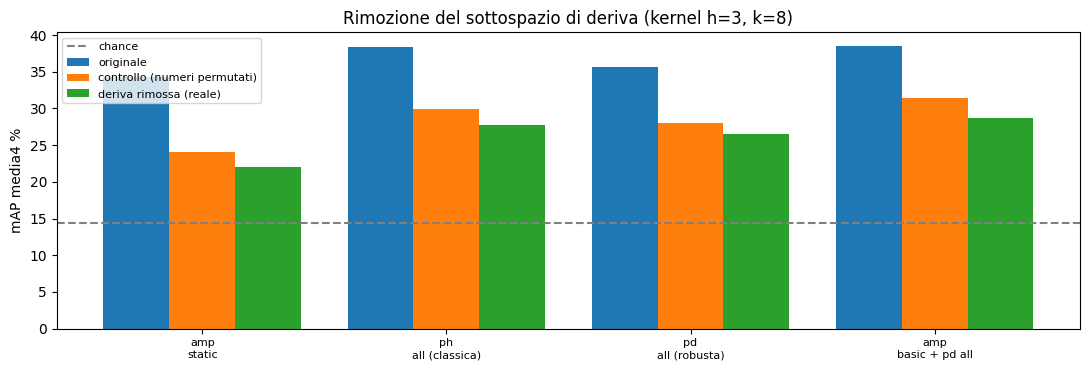

In [6]:
def subj_number(s):
    m = re.search(r'(\d+)$', s); return int(m.group(1)) if m else None

subs = sorted(set(rec_sid), key=natural_key)
nums_raw = [subj_number(s) for s in subs]
HAS_NUMS = all(n is not None for n in nums_raw)
if not HAS_NUMS:
    print('Nomi soggetto senza numero finale: salto §6-§7.')
else:
    num_of = dict(zip(subs, [float(n) for n in nums_raw]))

    def trend_matrix(M, nums, method, param):
        # trend lento delle medie per soggetto M [n_sub, d] in funzione del numero soggetto
        if method == 'kernel':
            W = np.exp(-0.5 * ((nums[:, None] - nums[None, :]) / param) ** 2)
            return (W / W.sum(1, keepdims=True)) @ M
        if method == 'poly':
            x = (nums - nums.mean()) / (nums.std() + 1e-12)
            V = np.vander(x, int(param) + 1, increasing=True)
            return V @ np.linalg.lstsq(V, M, rcond=None)[0]
        raise ValueError(method)

    def drift_basis(Mtr, nums_tr, method, param, k):
        T = trend_matrix(Mtr, nums_tr, method, param); T = T - T.mean(0)
        U, S, Vt = np.linalg.svd(T, full_matrices=False)
        k_eff = int(min(k, (S > 1e-6 * S[0]).sum())) if S[0] > 0 else 0
        V = Vt[:k_eff].T
        Mc = Mtr - Mtr.mean(0)
        share = float((np.linalg.norm(Mc @ V) ** 2) / (np.linalg.norm(Mc) ** 2 + 1e-12)) if k_eff else 0.0
        return V, share, k_eff

    def run_cv_proj(X, method, param, k, order_by_sid=None, rng_perm=None):
        # per ogni fold: standardizza, stima il sottospazio di deriva sul TRAINING, proietta tutto, LDA. Nessun numero di test usato.
        res, shares, keffs = [], [], []
        for tr, te in folds:
            mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-8
            Z = (X - mu) / sd
            subs_tr = sorted(set(rec_sid[tr]), key=natural_key)
            Mtr = np.stack([Z[tr][rec_sid[tr] == s].mean(0) for s in subs_tr])
            nums_tr = np.array([num_of[s] for s in subs_tr])
            if rng_perm is not None:
                nums_tr = rng_perm.permutation(nums_tr)                       # controllo: numeri permutati fra i soggetti di training
            V, share, k_eff = drift_basis(Mtr, nums_tr, method, param, k)
            Zp = Z - (Z @ V) @ V.T if k_eff else Z
            lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto').fit(Zp[tr], rec_sid[tr])
            E = l2(lda.transform(Zp))
            res.append(eval_protocols(E[te], rec_sid[te], rec_act[te])); shares.append(share); keffs.append(k_eff)
        return res, float(np.mean(shares)), float(np.mean(keffs))

    def vname(v): return f'{v[0]} {"h" if v[0] == "kernel" else "grado"}={v[1]}'
    def fold_scores(res): return np.array([mean_map(r) for r in res])

    DETREND_SETS = [s for s in ['amp static', 'ph all (classica)', 'pd all (robusta)', 'amp basic + pd all', 'DIAG ph_sto (hardware)'] if s in XS]
    rows = []; t0 = time.time()
    for sname in DETREND_SETS:
        X = XS[sname]; base_f = fold_scores(store[sname]); a0 = aggregate_folds(store[sname])
        for v in CFG['detrend_variants']:
            for k in CFG['drift_k']:
                if k > max(1, X.shape[1] // 2):                      # set a poche dimensioni: rimuovere k direzioni distruggerebbe tutto
                    continue
                real, sh_r, ke = run_cv_proj(X, v[0], v[1], k)
                ctrl_runs = [run_cv_proj(X, v[0], v[1], k, rng_perm=np.random.RandomState(CFG['seed'] + 100 + c)) for c in range(CFG['n_ctrl'])]
                real_f = fold_scores(real); ar = aggregate_folds(real)
                ctrl_f = np.mean([fold_scores(c[0]) for c in ctrl_runs], axis=0)
                ctrl_r1 = np.mean([aggregate_folds(c[0])[('cross', 'rank1')] for c in ctrl_runs])
                sh_c = np.mean([c[1] for c in ctrl_runs]); loss = ctrl_f - real_f; above = base_f.mean() - chance_mean4
                rows.append({'feature': sname, 'variante': vname(v), 'k': k, 'k eff.': ke,
                             'mAP originale': base_f.mean(), 'mAP reale': real_f.mean(), 'mAP controllo': ctrl_f.mean(),
                             'perdita netta': loss.mean(), '± std fold': loss.std(),
                             '% sopra chance': 100 * loss.mean() / above if above > 1 else np.nan,
                             'var. soggetti in V (reale %)': 100 * sh_r, 'var. soggetti in V (ctrl %)': 100 * sh_c,
                             'cross R1 orig': a0[('cross', 'rank1')], 'cross R1 reale': ar[('cross', 'rank1')], 'cross R1 ctrl': ctrl_r1})
    detr = pd.DataFrame(rows).set_index(['feature', 'variante', 'k'])
    print(f'{time.time() - t0:.0f}s | chance mAP media4 = {chance_mean4:.1f} | {CFG["n_ctrl"]} permutazioni di controllo')
    print('"var. soggetti in V": quota della varianza fra soggetti (training) che cade nel sottospazio rimosso. Reale >> controllo = deriva forte.')
    display(detr.round(1))

    main_v = vname(CFG['detrend_variants'][0]); main_k = CFG['drift_k'][len(CFG['drift_k']) // 2]
    sub_t = detr.xs((main_v, main_k), level=('variante', 'k'))
    fig, ax = plt.subplots(figsize=(11, 3.8)); x = np.arange(len(sub_t)); w = 0.27
    ax.bar(x - w, sub_t['mAP originale'], w, label='originale'); ax.bar(x, sub_t['mAP controllo'], w, label='controllo (numeri permutati)')
    ax.bar(x + w, sub_t['mAP reale'], w, label='deriva rimossa (reale)'); ax.axhline(chance_mean4, color='gray', ls='--', label='chance')
    ax.set_xticks(x); ax.set_xticklabels([t.replace(' ', '\n', 1) for t in sub_t.index], fontsize=8); ax.set_ylabel('mAP media4 %')
    ax.set_title(f'Rimozione del sottospazio di deriva ({main_v}, k={main_k})'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. Dopo la proiezione: la deriva è sparita? Gli errori sono ancora fra soggetti vicini?

In [7]:
if HAS_NUMS:
    order_i = np.argsort([num_of[s] for s in subs]); n_sub = len(subs)
    nums_sorted = np.array([num_of[subs[i]] for i in order_i])
    lag = np.abs(nums_sorted[:, None] - nums_sorted[None, :]); iu = np.triu_indices(n_sub, 1)
    rl = rankdata(lag[iu]); rl = rl - rl.mean()
    B = CFG['drift_perms']; prng = np.random.RandomState(CFG['seed'])
    perms = [np.arange(n_sub)] + [prng.permutation(n_sub) for _ in range(B)]
    big = np.eye(n_sub) * 1e9

    def drift_stats(D):
        rho, nn = [], []
        for p in perms:
            Dp = D[np.ix_(p, p)]
            rd = rankdata(Dp[iu]); rd = rd - rd.mean()
            rho.append((rl * rd).sum() / np.sqrt((rl ** 2).sum() * (rd ** 2).sum()))
            nn.append(lag[np.arange(n_sub), np.argmin(Dp + big, axis=1)].mean())
        rho, nn = np.array(rho), np.array(nn)
        return rho[0], (1 + (rho[1:] >= rho[0]).sum()) / (1 + B), (1 + (nn[1:] <= nn[0]).sum()) / (1 + B)

    def subject_dist(Zrec):
        M = np.stack([Zrec[rec_sid == subs[i]].mean(0) for i in order_i]); M = l2(M - M.mean(0))
        return 1 - M @ M.T

    main_variant = CFG['detrend_variants'][0]; main_k = CFG['drift_k'][len(CFG['drift_k']) // 2]
    drift_rows = []
    for g in ['static', 'diff', 'ph_static', 'ph_std', 'ph_diff', 'pd_static', 'pd_std', 'pd_diff', 'ph_sto']:
        Xg = feat[g]; Z0 = (Xg - Xg.mean(0)) / (Xg.std(0) + 1e-8)
        r0, p0, q0 = drift_stats(subject_dist(Z0))
        M_all = np.stack([Z0[rec_sid == s].mean(0) for s in subs]); nums_all = np.array([num_of[s] for s in subs])
        V, _, _ = drift_basis(M_all, nums_all, main_variant[0], main_variant[1], main_k)       # solo diagnostica: stimata su tutti i soggetti
        r1, p1, q1 = drift_stats(subject_dist(Z0 - (Z0 @ V) @ V.T))
        drift_rows.append({'gruppo': g, 'Spearman orig': r0, 'p orig': p0, 'p vicini orig': q0,
                           f'Spearman dopo ({vname(main_variant)}, k={main_k})': r1, 'p dopo': p1, 'p vicini dopo': q1})
    print(f'Test di deriva (permutazioni) prima e dopo la proiezione (in-sample, solo per verificare che rimuova la deriva). Bonferroni su 9 gruppi: p < {0.05 / 9:.4f}')
    display(pd.DataFrame(drift_rows).set_index('gruppo').round(3))

    def wrong_top1(E, sid, act, protocol):
        G, Pm = act == GAL, act == PRB
        if protocol == 'cross': q_idx, g_idx, ex = np.where(Pm)[0], np.where(G)[0], False
        else:                   q_idx, g_idx, ex = np.where(G)[0], np.where(G)[0], True
        sim = E[q_idx] @ E[g_idx].T
        if ex: sim[np.arange(len(q_idx)), np.arange(len(q_idx))] = -np.inf
        top = g_idx[np.argmax(sim, axis=1)]
        ids_here = sorted(set(sid[q_idx]), key=natural_key); obs, exp = [], []
        for qi, ti in zip(q_idx, top):
            if sid[qi] != sid[ti]:
                obs.append(abs(num_of[sid[qi]] - num_of[sid[ti]]))
                exp.append(np.mean([abs(num_of[sid[qi]] - num_of[s]) for s in ids_here if s != sid[qi]]))
        return obs, exp

    def fold_embeddings(X, project):
        # embedding LDA per fold; se project=True la deriva è rimossa con V stimato sul solo training del fold
        for tr, te in folds:
            mu, sd = X[tr].mean(0), X[tr].std(0) + 1e-8
            Z = (X - mu) / sd
            if project:
                subs_tr = sorted(set(rec_sid[tr]), key=natural_key)
                Mtr = np.stack([Z[tr][rec_sid[tr] == s].mean(0) for s in subs_tr]); nums_tr = np.array([num_of[s] for s in subs_tr])
                V, _, ke = drift_basis(Mtr, nums_tr, main_variant[0], main_variant[1], main_k)
                if ke: Z = Z - (Z @ V) @ V.T
            lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto').fit(Z[tr], rec_sid[tr])
            yield te, l2(lda.transform(Z))[te]

    loc_rows = []; brng = np.random.RandomState(0)
    for sname in [s for s in ['amp static', 'ph all (classica)', 'pd all (robusta)'] if s in XS]:
        for label, project in [('originale', False), (f'deriva rimossa ({vname(main_variant)}, k={main_k})', True)]:
            for protocol in ['cross', f'same_{GAL}']:
                obs, exp = [], []
                for te, E in fold_embeddings(XS[sname], project):
                    o, e = wrong_top1(E, rec_sid[te], rec_act[te], protocol); obs += o; exp += e
                d = np.array(obs) - np.array(exp)
                if len(d) == 0: continue
                boot = [brng.choice(d, len(d)).mean() for _ in range(2000)]
                loc_rows.append({'feature': sname, 'versione': label, 'protocollo': protocol, 'top-1 sbagliati': len(d),
                                 '|Δnum| osservato': np.mean(obs), 'atteso a caso': np.mean(exp), 'differenza': d.mean(),
                                 'IC95': f'[{np.percentile(boot, 2.5):.1f}, {np.percentile(boot, 97.5):.1f}]'})
    print('Top-1 sbagliati: |Δ numero soggetto| fra query e identità restituita (differenza < 0 con IC95 che esclude 0 = errori fra soggetti vicini):')
    display(pd.DataFrame(loc_rows).set_index(['feature', 'versione', 'protocollo']).round(2))

Test di deriva (permutazioni) prima e dopo la proiezione (in-sample, solo per verificare che rimuova la deriva). Bonferroni su 9 gruppi: p < 0.0056


,Spearman orig,p orig,p vicini orig,"Spearman dopo (kernel h=3, k=8)",p dopo,p vicini dopo
gruppo,,,,,,
static,0.010,0.279,0.020,-0.115,1.000,0.506
diff,0.213,0.001,0.001,-0.132,1.000,0.854
ph_static,0.095,0.012,0.003,-0.087,1.000,0.110
ph_std,0.304,0.000,0.002,-0.088,1.000,0.010
ph_diff,0.304,0.000,0.001,-0.100,1.000,0.008
pd_static,0.292,0.000,0.000,-0.112,1.000,0.149
pd_std,0.334,0.000,0.011,-0.136,1.000,0.399
pd_diff,0.324,0.000,0.019,-0.131,1.000,0.087
ph_sto,0.177,0.001,0.148,0.014,0.258,0.852


Top-1 sbagliati: |Δ numero soggetto| fra query e identità restituita (differenza < 0 con IC95 che esclude 0 = errori fra soggetti vicini):


top-1 sbagliati  |Δnum| osservato  atteso a caso  differenza          IC95
feature           versione                         protocollo                                                                             
amp static        originale                        cross                    154             12.79          15.43       -2.64  [-4.1, -1.3]
                                                   same_saluto              113             16.25          15.61        0.64   [-1.1, 2.4]
                  deriva rimossa (kernel h=3, k=8) cross                    179             15.25          15.36       -0.11   [-1.6, 1.5]
                                                   same_saluto              166             13.49          15.34       -1.85  [-3.3, -0.5]
ph all (classica) originale                        cross                    150             11.77          15.08       -3.31  [-4.8, -1.8]
                                                   same_saluto              109             12.91          15.20       -2.29  [-4.1, -0.5]
                  deriva rimossa (kernel h=3, k=8) cross                    166             14.17          15.25       -1.08   [-2.6, 0.4]
                                                   same_saluto              136             13.85          15.27       -1.42   [-3.0, 0.0]
pd all (robusta)  originale                        cross                    146             12.79          15.27       -2.49  [-3.9, -1.0]
                                                   same_saluto              126             11.56          15.14       -3.58  [-5.4, -1.8]
                  deriva rimossa (kernel h=3, k=8) cross                    170             14.94          15.30       -0.36   [-1.8, 1.1]
                                                   same_saluto              142             12.63          15.43       -2.80  [-4.3, -1.2]

## 8. Come leggere i risultati

* **§3:** se i salti di srotolamento correlano con il residuo classico ma non con la std robusta, la fase classica è inquinata. Se le righe `pd` (§5) superano `ph`, usa la fase robusta anche per la GNN.
* **§5, `pdn` contro `pd`:** mostra se togliere la componente comune per pacchetto (la pendenza) serve o toglie identità.
* **§6, perdita netta (controllo − reale):** ≈ 0 entro `± std fold` ⇒ rimuovere le vere direzioni di deriva non costa più che rimuovere direzioni casuali: l'accuratezza non dipende dal numero soggetto. Grande e positiva ⇒ quella parte era tempo/sessione. Guarda anche `var. soggetti in V`: se reale ≫ controllo la deriva è forte e il test ha potere; se sono uguali non c'è deriva da rimuovere.
* **`DIAG ph_sto`** (puro hardware) è la prova di sanità: dopo la proiezione dovrebbe scendere verso la chance più del suo controllo.
* **§7:** dopo la proiezione i p della deriva dovrebbero salire. Se gli errori restano fra soggetti vicini, la numerazione non cattura tutta la struttura temporale.
* **Sensibilità del test:** la proiezione rimuove solo poche direzioni *lisce* nel numero soggetto. Se ogni soggetto ha una firma di sessione ad alta dimensione e non liscia, o se l'identità è presente anche fuori dal sottospazio di deriva (feature a molte dimensioni), l'accuratezza resta alta anche con deriva reale (nei dati sintetici di validazione con deriva iniettata la perdita netta era grande per le feature a poche dimensioni e ≈ 0 per le feature ad alta dimensione). Perdita netta ≈ 0 quindi **non prova** l'assenza di effetto sessione: prova solo che non dipende da poche direzioni di deriva.
* **Limite che il test non supera:** se ogni soggetto è una sola sessione, persona e sessione sono confuse per costruzione. Un risultato "non spiegato dal numero" è una prova indiretta; per una dimostrazione servono soggetti registrati in sessioni diverse.
* Con 4 fold le deviazioni standard sono grossolane: considera interessanti solo perdite nette di diversi punti.